# Function 2 - Week 6: Model predictions

Use **15 official observations through round 5**, received on **30 October 2026**, to review the next query. All new model scores use the same held-out official targets. The [week-level report](../report.md) explains the results and records the course lifecycle.

Continuous output maximisation remains the task. GP UCB combines a fitted mean with model-dependent latent uncertainty.

Three small neural architectures, each with seeds 11, 42 and 73, remain in the comparison. Input and target scaling are fitted inside each leave-one-out fold. Architecture selection averages errors across seeds; neural seed spread is not GP posterior uncertainty. Model selection on these small, adaptively sampled datasets is provisional.


In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

repository_dir = next(folder for folder in Path.cwd().parents if (folder / "run-python.ps1").is_file())
expected_interpreter = repository_dir / ".venv" / "Scripts" / "python.exe"
if Path(sys.executable).resolve() != expected_interpreter.resolve():
    raise RuntimeError(f"Select the capstone-local kernel: {expected_interpreter}")
shared_dir = repository_dir / "stage-2-bbo/notebooks/Shared"
for folder in (shared_dir, shared_dir.parent / "Function_1/FunctionSpecificShared"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from exploration_review_helpers import load_exploration_review
from cohort_review_helpers import load_cohort_review
from model_helpers import make_models
from model_review_helpers import make_regression_models, review_latest_predictions, noise_sensitivity
from model_review_plots import plot_held_out_comparison
from surrogate_study_helpers import make_study_models, evaluate_regressors
from prediction_review_helpers import (
    select_gp, paired_peer_review, choose_training_scope, neural_architecture_review,
    make_candidate_review, review_gp_query, neural_candidate_review, neural_gradient_review,
)
from prediction_review_plots import plot_response_profiles, plot_score_planes
from neural_explorer import save_neural_explorer, network_prediction, gp_prediction
from function_1_model_helpers import signed_log
from query_budget import remaining_queries
print("Python interpreter:", sys.executable)


Python interpreter: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
# Declare settings before fitting; the existing Week 6 observation snapshot is immutable.
FUNCTION_NUMBER = 2
CURRENT_WEEK = 6
INPUT_COLUMNS = ['x1', 'x2']
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent if ANALYSIS_DIR.name == "official" else ANALYSIS_DIR
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
COHORT_PATH = WEEK_DIR / "cohort/observations.csv" if FUNCTION_NUMBER <= 4 else None
COHORT_AUDIT_PATH = WEEK_DIR / "cohort/data-audit.json"
EXPECTED_PEERS = 5
TITLE = f"Function {FUNCTION_NUMBER} - Week 6"
HEIGHT_SCALE = None
TARGET_LABEL = 'output y'
SELECTION_METRIC = 'LOO RMSE'
MODEL_SETTINGS = {'noise_fraction': 0.1, 'ridge_alpha': 1.0, 'kernel_ridge_alpha': 0.1, 'kernel_ridge_gamma': 1.0, 'length_scale': 0.3, 'length_scale_bounds': (0.03, 2.0), 'amplitude': 1.0, 'amplitude_bounds': (0.01, 100.0), 'optimiser_restarts': 3, 'seed': 42}
FIXED_MODEL_SETTINGS = None
FEATURE_SETS = {'GP: x1 only': (0,)}
MODEL_NAMES = ['Mean baseline', 'Linear regression', 'Ridge', 'Kernel ridge', 'Gaussian process', 'GP: x1 only', 'GP: separate length scales']
GP_NAMES = ['Gaussian process', 'GP: x1 only', 'GP: separate length scales']
ARCHITECTURES = [
    {"name": "tanh-8", "layers": [8], "activation": "tanh"},
    {"name": "tanh-16", "layers": [16], "activation": "tanh"},
    {"name": "relu-8-8", "layers": [8, 8], "activation": "relu"},
]
SEEDS = [11, 42, 73]
NEURAL_SETTINGS = dict(alpha=.1, max_iter=400, max_fun=15000, tolerance=1e-6, gp_restarts=3)
EXPLORATION_WEIGHT = 1.96
EXPLORATION_WEIGHTS = (0., 1., 1.96, 3.)
MIN_QUERY_DISTANCE = 0.0
SEARCH_SETTINGS = dict(broad_power=14, broad_seed=42, local_power=12, local_seed=43,
                       local_radius=.15, precision=6, include_corners=True)


In [3]:
review = load_exploration_review(DATA_PATH, input_columns=INPUT_COLUMNS,
                                       expected_round_counts=EXPECTED_ROUND_COUNTS)
data = review["data"]
inputs, raw_y = review["inputs"].to_numpy(), review["outputs"].to_numpy()
target = signed_log(raw_y, scale=HEIGHT_SCALE) if FUNCTION_NUMBER == 1 else raw_y.copy()
anchor = inputs[int(np.argmax(raw_y))].copy()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
peer_review = None
if COHORT_PATH is not None:
    audit = json.loads(COHORT_AUDIT_PATH.read_text(encoding="utf-8"))
    if hashlib.sha256(COHORT_PATH.read_bytes()).hexdigest() != audit["cohort_csv_sha256"]:
        raise ValueError("Retained peer snapshot hash mismatch")
    peer_review = load_cohort_review(COHORT_PATH, DATA_PATH, input_columns=INPUT_COLUMNS,
        expected_round_counts=EXPECTED_ROUND_COUNTS, expected_peer_count=EXPECTED_PEERS)
    peers = peer_review["data"].loc[peer_review["peer_mask"]]
    peer_inputs = peers[INPUT_COLUMNS].to_numpy()
    peer_raw = peers.y.to_numpy()
    peer_target = signed_log(peer_raw, scale=HEIGHT_SCALE) if FUNCTION_NUMBER == 1 else peer_raw
    known_inputs = peer_review["inputs"].to_numpy()
else:
    peer_inputs = np.empty((0, len(INPUT_COLUMNS)))
    peer_target = np.empty(0)
    known_inputs = inputs
display(pd.Series({"Official rows": len(data), "Retained peer rows": len(peer_inputs),
                   "Target units": TARGET_LABEL, "Query opportunities including Week 6": remaining_queries(WEEK_DIR)}))


Official rows                                 15
Retained peer rows                             5
Target units                            output y
Query opportunities including Week 6           8
dtype: object

### Fit the declared models

Leave-one-out errors compare like-for-like targets. Every estimator is refitted inside each fold; warnings remain in the saved review. The next-query policy selects among the declared GPs, retaining uncertainty-aware acquisition while testing neural predictive usefulness.

In [4]:
# Preserve each function's established families; add the declared neural comparators.
if FUNCTION_NUMBER == 1:
    models = make_models(**FIXED_MODEL_SETTINGS)
    adaptive = make_regression_models(len(INPUT_COLUMNS), **MODEL_SETTINGS)
    models.update({name: adaptive[name] for name in ["Gaussian process", "GP: separate length scales"]})
else:
    available = make_regression_models(len(INPUT_COLUMNS), feature_sets=FEATURE_SETS, **MODEL_SETTINGS)
    models = {name: available[name] for name in MODEL_NAMES}
if FUNCTION_NUMBER == 5:
    if not (raw_y > 0).all():
        raise ValueError("The existing log-target comparator needs positive observations")
    models["GP with log target (median)"] = TransformedTargetRegressor(
        regressor=clone(models["Gaussian process"]), func=np.log, inverse_func=np.exp)
neural_models, _, neural_metadata = make_study_models(len(INPUT_COLUMNS),
    architectures=ARCHITECTURES, seeds=SEEDS, **NEURAL_SETTINGS)
models.update({name: neural_models[name] for name in neural_metadata})
run = evaluate_regressors(models, inputs, target)
official_gp = select_gp(run, GP_NAMES, metric=SELECTION_METRIC)
networks = neural_architecture_review(run, neural_metadata, metric=SELECTION_METRIC)
display(run["table"].sort_values(SELECTION_METRIC).round(6))
display(networks["table"].round(6))


Regression complete: Mean baseline; warnings=0


Regression complete: Linear regression; warnings=0


Regression complete: Ridge; warnings=0


Regression complete: Kernel ridge; warnings=0


Regression complete: Gaussian process; warnings=0


...

Regression complete: NN relu-8-8 seed 11; warnings=0


Regression complete: NN relu-8-8 seed 42; warnings=0


Regression complete: NN relu-8-8 seed 73; warnings=1


,Model,LOO RMSE,LOO MAE,Rank correlation,Training RMSE,Fit warnings,RMSE / baseline
0,GP: separate length scales,0.123352,0.100644,0.832143,0.005184,2,0.590132
1,GP: x1 only,0.137221,0.108924,0.660714,0.007684,10,0.656481
2,Ridge,0.179408,0.138551,0.460714,0.154951,0,0.858311
3,Linear regression,0.179703,0.138596,0.521429,0.141726,0,0.859718
4,Kernel ridge,0.190978,0.146850,0.478571,0.134661,0,0.913663
5,Mean baseline,0.209025,0.172502,-1.000000,0.195090,0,1.000000
6,Gaussian process,0.218854,0.181450,-0.414286,0.002044,0,1.047023
7,NN relu-8-8 seed 73,0.224935,0.180794,0.414286,0.034011,1,1.076113
8,NN relu-8-8 seed 42,0.246241,0.194617,0.432143,0.059255,0,1.178043
9,NN relu-8-8 seed 11,0.258222,0.210309,0.375000,0.086826,0,1.235366


,architecture,mean,std,min,max
0,relu-8-8,0.243133,0.016860,0.224935,0.258222
1,tanh-16,0.275906,0.006932,0.271704,0.283907
2,tanh-8,0.278811,0.001550,0.277883,0.280600


### Compare official and retained-peer training

Peer-assisted fits hold out each official row and add only the previously audited peer rows to its training set. Compare both scopes on the same official targets; peer outputs do not change official progress or query allowance. Ties retain official-only training.

In [5]:
peer_run = None
if peer_review is not None:
    peer_run = paired_peer_review({name: models[name] for name in GP_NAMES}, inputs,
        peer_inputs, target, peer_target, run)
    display(peer_run["table"].round(6))
selected = choose_training_scope(run, GP_NAMES, peer_run=peer_run, metric=SELECTION_METRIC)
selected_model = selected["model"]
fit_inputs = known_inputs if selected["scope"] == "official_plus_retained_peers" else inputs
selected_predictions = (peer_run["predictions"][selected["name"]]
                        if selected["scope"] == "official_plus_retained_peers" else run["predictions"][selected["name"]])
neural_metrics = {"LOO RMSE": root_mean_squared_error(target, networks["predictions"]),
                  "LOO MAE": mean_absolute_error(target, networks["predictions"])}
display(pd.Series({"Selected GP": selected["name"], "Training scope": selected["scope"],
    "Selection metric": SELECTION_METRIC, "Selected GP official-target error": selected["error"],
    "Neural architecture": networks["architecture"], "Neural seed-mean official-target error": neural_metrics[SELECTION_METRIC]}))


Peer-assisted official-target review complete: Gaussian process


Peer-assisted official-target review complete: GP: x1 only


Peer-assisted official-target review complete: GP: separate length scales


,Model,Official LOO RMSE,Peer-assisted LOO RMSE,Official LOO MAE,Peer-assisted LOO MAE,Fit warnings
0,Gaussian process,0.218854,0.169839,0.181450,0.137982,0
1,GP: x1 only,0.137221,0.116460,0.108924,0.086248,13
2,GP: separate length scales,0.123352,0.111379,0.100644,0.085361,2


Selected GP                                 GP: separate length scales
Training scope                            official_plus_retained_peers
Selection metric                                              LOO RMSE
Selected GP official-target error                             0.111379
Neural architecture                                           relu-8-8
Neural seed-mean official-target error                        0.234339
dtype: object

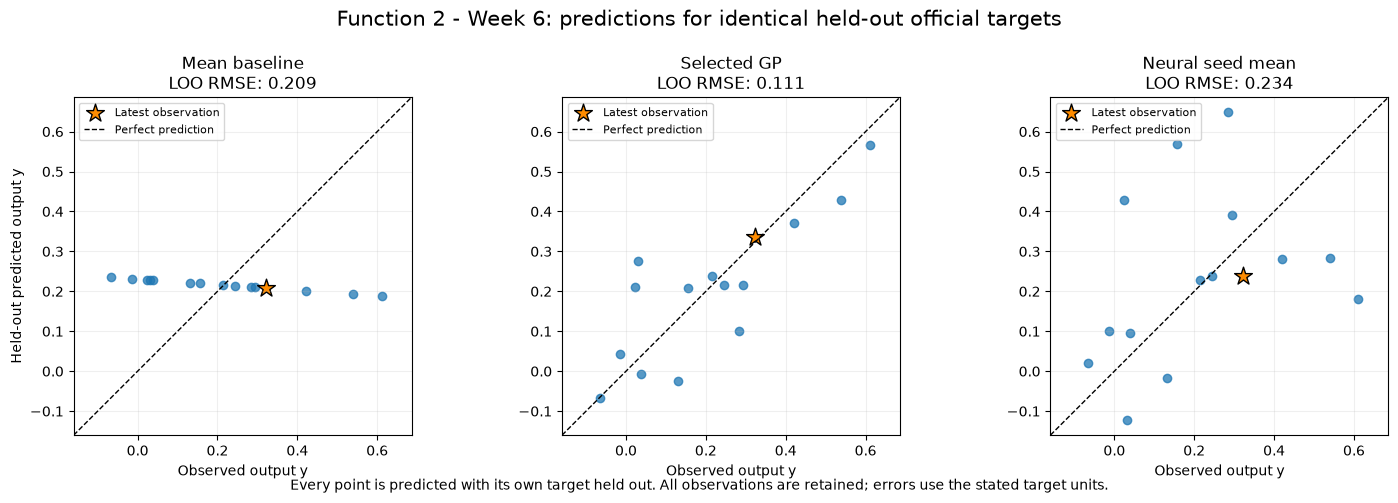

,Model,Latest held-out prediction,Latest error,Latest absolute error (%),Latest share of squared error (%),Other rows LOO RMSE
0,Selected GP,0.336453,0.013946,4.324134,0.104515,0.115228
1,Neural seed mean,0.239350,-0.083158,25.784807,0.839513,0.241544


In [6]:
display(plot_held_out_comparison(
    {"Mean baseline": run["predictions"]["Mean baseline"],
     "Selected GP": selected_predictions, "Neural seed mean": networks["predictions"]},
    target, model_names=["Mean baseline", "Selected GP", "Neural seed mean"],
    latest_mask=review["latest_mask"], target_label=TARGET_LABEL,
    title=f"{TITLE}: predictions for identical held-out official targets",
    save_to=FIGURES_DIR / "model-validation.png"))
display(review_latest_predictions({"Selected GP": selected_predictions,
    "Neural seed mean": networks["predictions"]}, target, review["latest_mask"]).round(6))


### Review the next query on a common candidate pool

Retain the seeded broad and incumbent-local candidate searches, six-decimal bounds and duplicate exclusions. The geometric comparator is the farthest eligible point in this frozen pool; it is a finite-pool coverage proxy. Neural alternatives maximise mean predictions across seeds. GP UCB uses latent posterior SD. Neither score is a new function evaluation.

In [7]:
candidates, coverage_point = make_candidate_review(inputs, anchor,
    input_columns=INPUT_COLUMNS, search_settings=SEARCH_SETTINGS,
    minimum_distance=MIN_QUERY_DISTANCE, excluded_inputs=known_inputs)
query_run = review_gp_query(selected, candidates, known_inputs, target,
    input_columns=INPUT_COLUMNS, weights=EXPLORATION_WEIGHTS, weight=EXPLORATION_WEIGHT,
    feature_sets=FEATURE_SETS, minimum_distance=MIN_QUERY_DISTANCE, training_inputs=fit_inputs)
proposal, scored = query_run["proposal"], query_run["scores"]
next_query = np.asarray(proposal["point"])
neural_proposal = neural_candidate_review(networks, candidates, input_columns=INPUT_COLUMNS)
display(pd.Series(proposal))
display(pd.Series(neural_proposal))
display(scored.head(5)[[*INPUT_COLUMNS, "posterior_mean", "posterior_sd", "ucb", "candidate_source", "nearest_observed_distance"]])


point                         [0.70052, 0.000114]
predicted_output                         0.588435
posterior_std                            0.093471
ucb                                      0.771638
predicted_mean_improvement               -0.02277
inside_sampled_hull                         False
portal_input                    0.700520-0.000114
nearest_observed_distance                 0.12863
dtype: object

point                                              [0.670394, 0.122929]
predicted_target                                                0.52456
seed_prediction_sd                                             0.022139
architecture                                                   relu-8-8
portal_input                                          0.670394-0.122929
criterion             mean prediction across all declared seeds; not...
dtype: object

,x1,x2,posterior_mean,posterior_sd,ucb,candidate_source,nearest_observed_distance
0,0.700520,0.000114,0.588435,0.093471,0.771638,Full input space,0.128630
1,0.697956,0.014708,0.595435,0.089077,0.770026,Full input space,0.113895
2,0.701930,0.017844,0.585822,0.093553,0.769185,Full input space,0.112107
3,0.703763,0.004828,0.579152,0.096406,0.768108,Full input space,0.125043
4,0.700103,0.047901,0.592875,0.089064,0.767441,Full input space,0.083445


In [8]:
# Use the same frozen pool and mean/SD values for every exploration weight.
display(query_run["weight_sensitivity"].round(6))
scope_proposals = {"selected": {"scope": selected["scope"], "model": selected["name"], **proposal}}
if peer_run is not None:
    alternative = (dict(official_gp, scope="official") if selected["scope"] != "official" else
                   choose_training_scope(run, GP_NAMES, peer_run=peer_run, metric=SELECTION_METRIC))
    # If the official fit won, still record the best peer-assisted GP's common-pool alternative.
    if selected["scope"] == "official":
        col = "Peer-assisted " + SELECTION_METRIC
        peer_name = peer_run["table"].set_index("Model")[col].idxmin()
        alternative = dict(name=peer_name, model=peer_run["fitted"][peer_name], scope="official_plus_retained_peers")
    alternative_inputs = known_inputs if alternative["scope"] != "official" else inputs
    alt = review_gp_query(alternative, candidates, known_inputs, target, input_columns=INPUT_COLUMNS,
        weights=EXPLORATION_WEIGHTS, weight=EXPLORATION_WEIGHT, feature_sets=FEATURE_SETS,
        minimum_distance=MIN_QUERY_DISTANCE, training_inputs=alternative_inputs)
    scope_proposals["alternative"] = {"scope": alternative["scope"], "model": alternative["name"], **alt["proposal"]}
    display(pd.DataFrame(scope_proposals).T)
regularisation_review = None
if FUNCTION_NUMBER in (2, 5, 6, 7, 8):
    training_target = np.r_[target, peer_target] if selected["scope"] != "official" else target
    regularisation_review = noise_sensitivity(selected_model, fit_inputs, training_target, next_query,
        fractions=(.03, .10, .30), fitted_noise_fraction=.10)
    display(regularisation_review.rename(columns={"Assumed noise fraction": "GP regularisation fraction"}).round(6))
if FUNCTION_NUMBER == 5:
    from scipy.spatial.distance import cdist
    all_candidates, _ = make_candidate_review(inputs, anchor, input_columns=INPUT_COLUMNS,
        search_settings=SEARCH_SETTINGS, minimum_distance=0.)
    from model_review_helpers import score_review_candidates
    spacing_scores = score_review_candidates(selected_model, all_candidates,
        input_columns=INPUT_COLUMNS, weight=EXPLORATION_WEIGHT)
    spacing_rows = []
    for minimum in (0., .01, .02, .05):
        top = spacing_scores.loc[spacing_scores.nearest_observed_distance >= minimum].iloc[0]
        spacing_rows.append({"Minimum distance": minimum,
            "Portal input": "-".join(f"{top[c]:.6f}" for c in INPUT_COLUMNS),
            "Nearest observed distance": top.nearest_observed_distance,
            "Predicted target": top.posterior_mean, "UCB": top.ucb})
    spacing_review = pd.DataFrame(spacing_rows)
    display(spacing_review)


,Weight,x1,x2,Predicted output,Posterior SD
0,0.00,0.693233,0.472984,0.617384,0.044499
1,1.00,0.696437,0.028655,0.599146,0.085814
2,1.96,0.700520,0.000114,0.588435,0.093471
3,3.00,0.700520,0.000114,0.588435,0.093471


,scope,model,point,predicted_output,posterior_std,ucb,predicted_mean_improvement,inside_sampled_hull,portal_input,nearest_observed_distance
selected,official_plus_retained_peers,GP: separate length scales,"[0.70052, 0.000114]",0.588435,0.093471,0.771638,-0.02277,False,0.700520-0.000114,0.12863
alternative,official,GP: separate length scales,"[0.710232, 0.011611]",0.580559,0.086236,0.749582,-0.030646,False,0.710232-0.011611,0.120825


C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


,GP regularisation fraction,Predicted output,Posterior SD
0,0.03,0.595322,0.110565
1,0.10,0.588435,0.093471
2,0.30,0.570585,0.081314


### Inspect conditional responses and neural input gradients

Every omitted coordinate is held fixed. Only measurements actually on a slice are plotted on its curve. The GP band and neural seed band describe different quantities. Input gradients are checked against finite differences and describe a fitted model, not causal effects.

At a near-zero ReLU activation, central differences may cross a kink. Such anchor checks are marked explicitly; implementation checks then use a declared nearby smooth probe. The anchor derivative is not presented as validated.

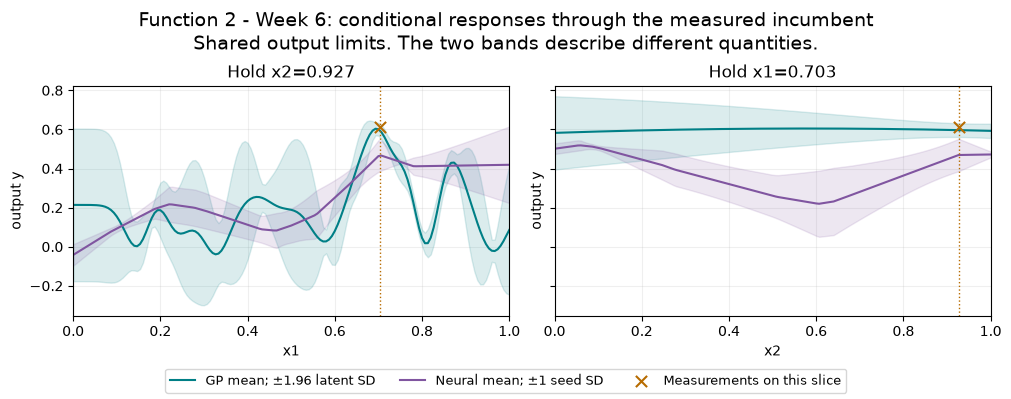

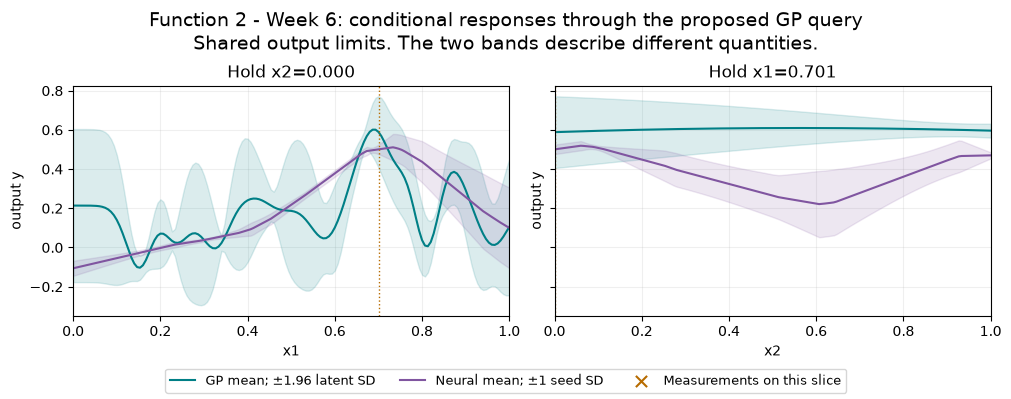

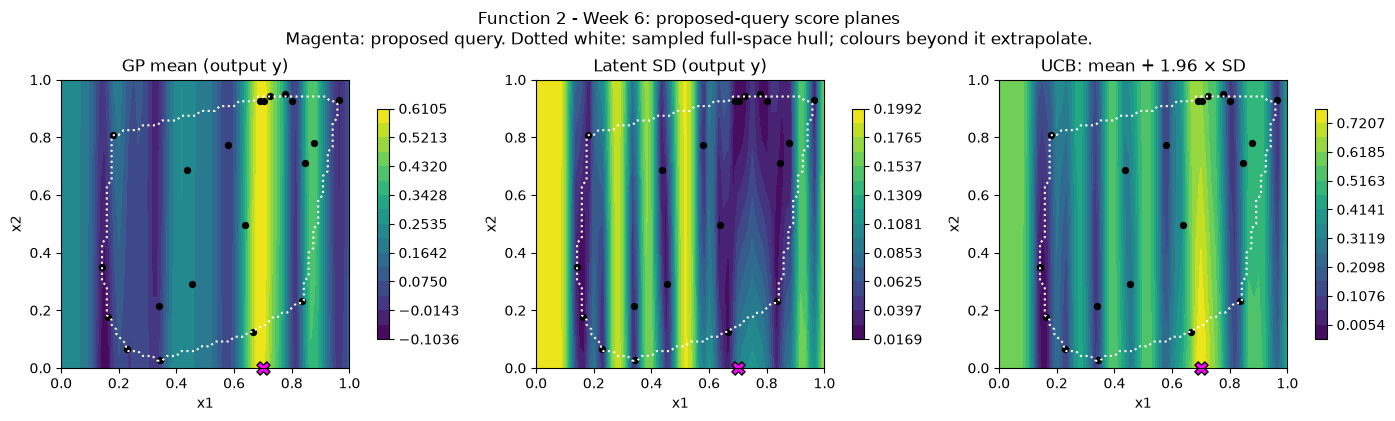

,Model,maximum_relative_error,passes,check_location,check_point,anchor_relative_error,anchor_check_passes
0,NN relu-8-8 seed 11,5.851652e-12,True,anchor,"[0.7026365569244406, 0.9265641975455574]",5.851652e-12,True
1,NN relu-8-8 seed 42,2.962943e-10,True,nearby smooth probe; anchor is near a ReLU kink,"[0.7027365569244406, 0.9267641975455574]",2.048495e+00,False
2,NN relu-8-8 seed 73,5.001773e-10,True,nearby smooth probe; anchor is near a ReLU kink,"[0.7027365569244406, 0.9267641975455574]",1.056189e+00,False


,x1,x2
Model,,
NN relu-8-8 seed 11,0.867089,0.981300
NN relu-8-8 seed 42,-0.712378,0.150781
NN relu-8-8 seed 73,-2.380704,-0.789686


In [9]:
display(plot_response_profiles(selected_model, networks["models"], inputs, target, anchor,
    input_columns=INPUT_COLUMNS, target_label=TARGET_LABEL,
    title=f"{TITLE}: conditional responses through the measured incumbent",
    save_to=FIGURES_DIR / "model-response-incumbent.png"))
display(plot_response_profiles(selected_model, networks["models"], inputs, target, next_query,
    input_columns=INPUT_COLUMNS, target_label=TARGET_LABEL,
    title=f"{TITLE}: conditional responses through the proposed GP query",
    save_to=FIGURES_DIR / "model-response-proposal.png"))
if len(INPUT_COLUMNS) <= 3:
    display(plot_score_planes(selected_model, fit_inputs, next_query, input_columns=INPUT_COLUMNS,
        target_label=TARGET_LABEL, title=f"{TITLE}: proposed-query score planes",
        weight=EXPLORATION_WEIGHT, save_to=FIGURES_DIR / "model-query-planes.png"))
gradient_review = neural_gradient_review(networks, anchor)
display(gradient_review.drop(columns="gradient"))
if not gradient_review.passes.all():
    raise ValueError("A neural input-gradient parity check failed; inspect before interpreting it")
display(pd.DataFrame([row for row in gradient_review.gradient], columns=INPUT_COLUMNS,
                     index=gradient_review.Model))


### Interactive GP and neural input explorer

[Open the offline explorer](figures/neural-network-explorer.html). Change any input, choose a neural architecture, compare its three seeds with the GP, or reset to the measured incumbent or proposed query. Curves update from exported fitted weights. This tool performs no training, course evaluations or submissions.

In [10]:
gp_error = f"{selected['error']:.6g}"
validation_text = (f"Selected GP {SELECTION_METRIC} on official targets: {gp_error}. "
    f"Neural seed-mean {SELECTION_METRIC}: {neural_metrics[SELECTION_METRIC]:.6g}. "
    f"Network architecture selected by average error across seeds {SEEDS}.")
explorer = save_neural_explorer(FIGURES_DIR / "neural-network-explorer.html",
    models=run["fitted"], metadata=neural_metadata, selected_architecture=networks["architecture"],
    gp=selected_model, input_columns=INPUT_COLUMNS, anchor=anchor, proposal=next_query,
    title=f"{TITLE}: GP and neural input explorer", target_label=TARGET_LABEL,
    scope=selected["scope"], validation=validation_text)
# Check exported forward passes at observations, new proposals and domain boundaries.
test_points = np.vstack([inputs, next_query, np.zeros(len(INPUT_COLUMNS)), np.full(len(INPUT_COLUMNS), .999999)])
for architecture, specs in explorer["networks"].items():
    for spec in specs:
        name = next(name for name, settings in neural_metadata.items()
                    if settings["architecture"] == architecture and settings["seed"] == spec["seed"])
        np.testing.assert_allclose(network_prediction(spec, test_points), run["fitted"][name].predict(test_points), rtol=1e-10, atol=1e-9)
expected_mean, expected_sd = selected_model.predict(test_points, return_std=True)
actual_mean, actual_sd = gp_prediction(explorer["gp"], test_points)
np.testing.assert_allclose(actual_mean, expected_mean, rtol=1e-10, atol=1e-9)
np.testing.assert_allclose(actual_sd, expected_sd, rtol=1e-9, atol=1e-9)
print("Exported GP/neural predictions match the fitted Python models.")


Exported GP/neural predictions match the fitted Python models.


In [11]:
magnitude_review = None
if FUNCTION_NUMBER == 1:
    # Fit a separate activity explanation; it cannot choose the signed-score proposal.
    magnitude_models = {"Mean baseline": models["Mean baseline"], **{name: models[name] for name in GP_NAMES}}
    magnitude_review = evaluate_regressors(magnitude_models, inputs, np.abs(target))
    display(magnitude_review["table"].sort_values(SELECTION_METRIC).round(6))
    print("Magnitude explains activity only. The proposed query above maximises signed-score GP UCB.")


### Save a provisional proposal

Eight query opportunities remain, including Week 6. The saved model evidence supports review; it does not confirm portal submission. Held-out checks below are retrospective and remain distinct from the historical forecast checks in the observation notebook.

In [12]:
selected_gp = selected_model.steps[-1][1] if hasattr(selected_model, "steps") else selected_model
summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "analysis": "week_06_model_review",
    "observations": len(inputs), "official_observations": len(inputs), "retained_peer_observations": len(peer_inputs),
    "python_executable": sys.executable, "target_units": TARGET_LABEL, "height_scale": HEIGHT_SCALE,
    "best_observed_raw_output": float(raw_y.max()), "best_observed_target": float(target.max()),
    "query_model": selected["name"], "training_scope": selected["scope"],
    "selection_metric": SELECTION_METRIC, "official_target_error": selected["error"],
    "baseline_error": float(run["table"].set_index("Model").loc["Mean baseline", SELECTION_METRIC]),
    "proposal_status": "proposed_not_submitted", "remaining_queries": remaining_queries(WEEK_DIR),
    "portal_input": proposal["portal_input"], "point": proposal["point"], "proposal": proposal,
    "proposal_target_units": TARGET_LABEL, "ucb_weight": EXPLORATION_WEIGHT,
    "candidate_count": len(candidates), "minimum_query_distance": MIN_QUERY_DISTANCE,
    "coverage_proxy_point": coverage_point.tolist(), "search_settings": SEARCH_SETTINGS,
    "fitted_kernel": str(selected_gp.kernel_), "model_settings": MODEL_SETTINGS,
    "model_comparison": run["table"].to_dict(orient="records"),
    "model_warnings": run["warnings"], "held_out_predictions": {k: v.tolist() for k,v in run["predictions"].items()},
    "peer_comparison": None if peer_run is None else peer_run["table"].to_dict(orient="records"),
    "peer_warnings": None if peer_run is None else peer_run["warnings"],
    "scope_proposals": scope_proposals, "weight_sensitivity": query_run["weight_sensitivity"].to_dict(orient="records"),
    "regularisation_sensitivity": None if regularisation_review is None else regularisation_review.to_dict(orient="records"),
    "neural_architectures": ARCHITECTURES, "neural_seeds": SEEDS, "neural_settings": NEURAL_SETTINGS,
    "neural_architecture_comparison": networks["table"].to_dict(orient="records"),
    "selected_neural_architecture": networks["architecture"], "neural_ensemble_errors": neural_metrics,
    "neural_proposal": neural_proposal, "neural_gradient_checks": gradient_review.to_dict(orient="records"),
    "magnitude_comparison": None if magnitude_review is None else magnitude_review["table"].to_dict(orient="records"),
    "snapshot_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "cohort_audit_sha256": None if COHORT_PATH is None else hashlib.sha256(COHORT_AUDIT_PATH.read_bytes()).hexdigest(),
}
if FUNCTION_NUMBER == 5:
    summary["spacing_sensitivity"] = spacing_review.to_dict(orient="records")
text = json.dumps(summary, indent=2, allow_nan=False)
(ANALYSIS_DIR / "model-review.json").write_text(text + "\n", encoding="utf-8")
print(text)


{
  "function": 2,
  "week": 6,
  "analysis": "week_06_model_review",
  "observations": 15,
  "official_observations": 15,
  "retained_peer_observations": 5,
  "python_executable": "C:\\_Source\\Imperial-ML-AI-Live\\Capstone\\imperial-capstone\\.venv\\Scripts\\python.exe",
  "target_units": "output y",
  "height_scale": null,
  "best_observed_raw_output": 0.6112052157614438,
  "best_observed_target": 0.6112052157614438,
  "query_model": "GP: separate length scales",
  "training_scope": "official_plus_retained_peers",
  "selection_metric": "LOO RMSE",
  "official_target_error": 0.11137906268912874,
  "baseline_error": 0.20902513533204975,
  "proposal_status": "proposed_not_submitted",
  "remaining_queries": 8,
  "portal_input": "0.700520-0.000114",
  "point": [
    0.70052,
    0.000114
  ],
  "proposal": {
    "point": [
      0.70052,
      0.000114
    ],
    "predicted_output": 0.5884352358211425,
    "posterior_std": 0.09347082915265545,
    "ucb": 0.7716380609603473,
    "predicte